# 5. False alarms: the P-FFA on pure noise

A detection threshold means something only if the S/N of a trial is
calibrated: on data with no pulsar, the scores must follow a known
distribution, so the expected number of false alarms above any threshold
can be predicted.

This notebook runs the P-FFA on white noise and checks that:

1. the score of every trial follows the null distribution of a folded
   noise profile, simulated independently with loki's scorer;
2. the number of trials above a threshold matches the prediction;
3. the production sweep (notebook 4) publishes no candidates.

Runtime: about 10 seconds; memory: about 3 GB.

In [1]:
%matplotlib inline
from pathlib import Path

import numpy as np
from matplotlib import pyplot as plt
from scipy import stats

from loki import libloki
from loki.candidates import CandidateFile
from loki.libloki.configs import PulsarSearchConfig
from loki.search import ffa_search
from pyloki.io.timeseries import TimeSeries

libloki.set_log_level("warning")  # hide loki's per-step info messages
SEED = 1
NTHREADS = 4  # CPU threads; raise it on a machine of your own
OUTDIR = Path("_output/05_noise_statistics")
OUTDIR.mkdir(parents=True, exist_ok=True)

## Noise and search

2^22 samples of unit-variance white noise, searched over 100–200 Hz with
the settings of notebook 1 (64 bins, Fourier-domain shifts).

In [2]:
nsamps, tsamp = 2**22, 64e-6
rng = np.random.default_rng(SEED)
noise = TimeSeries(
    rng.standard_normal(nsamps).astype(np.float32),
    np.ones(nsamps, dtype=np.float32),
    tsamp,
)
search_cfg = PulsarSearchConfig(
    nsamps=nsamps,
    tsamp=tsamp,
    nbins=64,
    eta=1,
    param_limits=[(100.0, 200.0)],
    ducy_max=0.2,
    wtsp=1.5,
    nthreads=NTHREADS,
    use_fourier=True,
)
plan, pgram = ffa_search(noise, search_cfg)
scores = np.asarray(pgram.snrs)  # (frequency trials, widths)
widths = np.asarray(search_cfg.score_widths, dtype=np.uint64)
print(
    f"{scores.shape[0]:,} frequency trials x "
    f"{len(widths)} boxcar widths {widths.tolist()}",
)

1,717,987 frequency trials x 7 boxcar widths [1, 2, 3, 4, 6, 9, 12]


## Null distribution

For one trial, the P-FFA returns, per boxcar width, the highest S/N over
the 64 phases of the profile. With no signal, each folded bin is a
unit-variance Gaussian. The null model below draws 2^21 such profiles
and scores them with the same widths using `libloki.scores.snr_boxcar_2d`,
which never touches the P-FFA.

The per-width means and standard deviations of the two must agree.

In [3]:
profiles = rng.standard_normal((2**21, search_cfg.nbins)).astype(np.float32)
null = libloki.scores.snr_boxcar_2d(profiles, widths, 1.0, NTHREADS)

print(
    f"{'width':>5}  {'mean P-FFA':>10}  {'mean null':>9}  "
    f"{'std P-FFA':>9}  {'std null':>8}",
)
for i, w in enumerate(widths):
    print(
        f"{w:5d}  {scores[:, i].mean():10.3f}  {null[:, i].mean():9.3f}  "
        f"{scores[:, i].std():9.3f}  {null[:, i].std():8.3f}",
    )

width  mean P-FFA  mean null  std P-FFA  std null
    1       2.351      2.363      0.434     0.437
    2       2.325      2.326      0.450     0.451
    3       2.273      2.277      0.464     0.465
    4       2.231      2.230      0.477     0.477
    6       2.148      2.148      0.495     0.494
    9       2.047      2.052      0.515     0.514
   12       1.975      1.977      0.528     0.527


## Tail and expected false alarms

A trial's score is its best S/N over widths. Its survival function, the
fraction of trials above a threshold, is shown for the P-FFA, for the null
model, and as an analytic bound: the trial maximises over 64 phases × 7
widths of standard normal scores, so P(score > t) ≤ 448 Q(t), with Q the
Gaussian tail. The bound is loose at low S/N, where the scores are
strongly correlated, and tight in the tail, which is the part that
matters for a threshold.

Neighbouring trials share data, so their scores are correlated. That does
not change the expected number of trials above a threshold (trials ×
survival probability), but the exceedances come in groups of adjacent
trials, one group per noise fluctuation, so the counts scatter more than
Poisson counts would. The table counts both trials and groups; the null
model column is left empty where its 2^21 samples are too few.

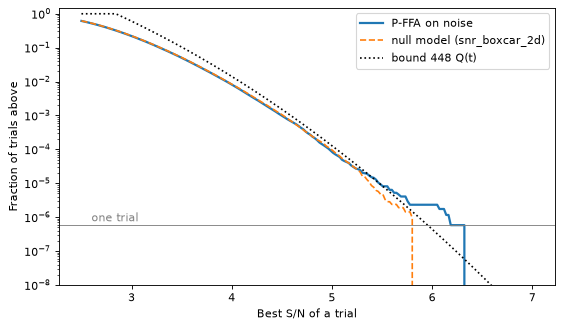

threshold   trials  groups  expected (null)    bound
      4.0    14031    6273          14488.4  24376.0
      4.5     1699     792           1817.8   2615.0
      5.0      147      83            166.3    220.6
      5.5       15       6              8.2     14.6
      6.0        4       1                -      0.8
highest score on noise: 6.32


In [4]:
best = scores.max(axis=1)
best_null = null.max(axis=1)
ntrials = len(best)
n_templates = search_cfg.nbins * len(widths)

t = np.linspace(2.5, 7.0, 200)
sf_ffa = (best[:, None] > t).mean(axis=0)
sf_null = (best_null[:, None] > t).mean(axis=0)
bound = np.minimum(n_templates * stats.norm.sf(t), 1)

fig, ax = plt.subplots(figsize=(8, 4.5), dpi=80)
ax.semilogy(t, sf_ffa, label="P-FFA on noise", lw=2)
ax.semilogy(t, sf_null, "--", label="null model (snr_boxcar_2d)")
ax.semilogy(t, bound, ":", c="k", label=f"bound {n_templates} Q(t)")
ax.axhline(1 / ntrials, c="gray", lw=0.8)
ax.text(2.6, 1.3 / ntrials, "one trial", color="gray")
ax.set_xlabel("Best S/N of a trial")
ax.set_ylabel("Fraction of trials above")
ax.set_ylim(1e-8, 1.5)
ax.legend()
plt.show()

print(
    f"{'threshold':>9}  {'trials':>7}  {'groups':>6}  "
    f"{'expected (null)':>15}  {'bound':>7}",
)
for thr in (4.0, 4.5, 5.0, 5.5, 6.0):
    above = np.flatnonzero(best > thr)
    groups = int(len(above) > 0) + int(np.sum(np.diff(above) > 2))
    n_null = int((best_null > thr).sum())
    expected = f"{ntrials * n_null / len(best_null):.1f}" if n_null >= 10 else "-"
    upper = ntrials * n_templates * stats.norm.sf(thr)
    print(f"{thr:9.1f}  {len(above):7d}  {groups:6d}  {expected:>15}  {upper:7.1f}")
print(f"highest score on noise: {best.max():.2f}")

## The production sweep on noise

`FFAFreqSweep` over 25–200 Hz with the default threshold `snr_min = 7`.
Below 100 Hz the planner folds with 128 and 256 bins and more widths,
which raises the bound per trial; even for 256 bins it stays a few in
a billion. With a few million trials the expected number of false
candidates is far below one, and the candidate table should be empty.

In [5]:
sweep_cfg = PulsarSearchConfig(
    nsamps=nsamps,
    tsamp=tsamp,
    nbins=64,
    eta=1,
    param_limits=np.array([[25.0, 200.0]]),
    ducy_max=0.2,
    wtsp=1.5,
    nthreads=NTHREADS,
    snr_min=7.0,
)
observation = libloki.io.ObservationMetadata()
observation.dm = 0.0
sweep = libloki.ffa.FFAFreqSweep(sweep_cfg, show_progress=False)
sweep.execute(noise.ts_e, noise.ts_v, str(OUTDIR), "noise", observation=observation)

with CandidateFile(OUTDIR / "noise_ffa_results.h5") as candidates:
    print(f"candidates above S/N {sweep_cfg.snr_min}: {len(candidates)}")
for nbins, nwidths in ((64, 7), (256, 11)):
    print(
        f"bound per trial above 7 ({nbins} bins): "
        f"{nbins * nwidths * stats.norm.sf(7.0):.1e}",
    )

candidates above S/N 7.0: 0
bound per trial above 7 (64 bins): 5.7e-10
bound per trial above 7 (256 bins): 3.6e-09
